In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("train.csv")
df.head(10)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0.0,EDUCATION,B,6000,11.49,0.17,N,14,0
1,1,22,56000,OWN,6.0,MEDICAL,C,4000,13.35,0.07,N,2,0
2,2,29,28800,OWN,8.0,PERSONAL,A,6000,8.90,0.21,N,10,0
3,3,30,70000,RENT,14.0,VENTURE,B,12000,11.11,0.17,N,5,0
4,4,22,60000,RENT,2.0,MEDICAL,A,6000,6.92,0.10,N,3,0
5,5,27,45000,RENT,2.0,VENTURE,A,9000,8.94,0.20,N,5,0
6,6,25,45000,MORTGAGE,9.0,EDUCATION,A,12000,6.54,0.27,N,3,0
7,7,21,20000,RENT,0.0,PERSONAL,C,2500,13.49,0.13,Y,3,0
8,8,37,69600,RENT,11.0,EDUCATION,D,5000,14.84,0.07,Y,11,0
9,9,35,110000,MORTGAGE,0.0,DEBTCONSOLIDATION,C,15000,12.98,0.14,Y,6,0


In [3]:
df.shape

(58645, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          58645 non-null  int64  
 1   person_age                  58645 non-null  int64  
 2   person_income               58645 non-null  int64  
 3   person_home_ownership       58645 non-null  str    
 4   person_emp_length           58645 non-null  float64
 5   loan_intent                 58645 non-null  str    
 6   loan_grade                  58645 non-null  str    
 7   loan_amnt                   58645 non-null  int64  
 8   loan_int_rate               58645 non-null  float64
 9   loan_percent_income         58645 non-null  float64
 10  cb_person_default_on_file   58645 non-null  str    
 11  cb_person_cred_hist_length  58645 non-null  int64  
 12  loan_status                 58645 non-null  int64  
dtypes: float64(3), int64(6), str(4)
memory usa

In [5]:
# We will drop the id columns as it may confuse the model.
df = df.drop(['id'], axis=1)
df.head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,37,35000,RENT,0.0,EDUCATION,B,6000,11.49,0.17,N,14,0
1,22,56000,OWN,6.0,MEDICAL,C,4000,13.35,0.07,N,2,0
2,29,28800,OWN,8.0,PERSONAL,A,6000,8.90,0.21,N,10,0
3,30,70000,RENT,14.0,VENTURE,B,12000,11.11,0.17,N,5,0
4,22,60000,RENT,2.0,MEDICAL,A,6000,6.92,0.10,N,3,0
5,27,45000,RENT,2.0,VENTURE,A,9000,8.94,0.20,N,5,0
6,25,45000,MORTGAGE,9.0,EDUCATION,A,12000,6.54,0.27,N,3,0
7,21,20000,RENT,0.0,PERSONAL,C,2500,13.49,0.13,Y,3,0
8,37,69600,RENT,11.0,EDUCATION,D,5000,14.84,0.07,Y,11,0
9,35,110000,MORTGAGE,0.0,DEBTCONSOLIDATION,C,15000,12.98,0.14,Y,6,0


In [6]:
for col in df.columns:
    print(f"\nColumn Name: {col}")
    print(f"The Type of the data in {col} is: {df[col].dtype}")
    print(f"The Number of Unique values in {col} is : {df[col].nunique()}")
    if pd.api.types.is_numeric_dtype(df[col]):
        print(df[col].value_counts().head(10))
    else:
        print(df[col].value_counts())
    print("------------------------------")


Column Name: person_age
The Type of the data in person_age is: int64
The Number of Unique values in person_age is : 53
person_age
23    7726
22    7051
24    6395
25    5067
27    4450
26    3874
28    3707
29    3270
30    2333
31    1917
Name: count, dtype: int64
------------------------------

Column Name: person_income
The Type of the data in person_income is: int64
The Number of Unique values in person_income is : 2641
person_income
60000    4164
50000    2992
30000    2200
40000    1981
70000    1876
75000    1681
45000    1604
65000    1484
80000    1472
90000    1353
Name: count, dtype: int64
------------------------------

Column Name: person_home_ownership
The Type of the data in person_home_ownership is: str
The Number of Unique values in person_home_ownership is : 4
person_home_ownership
RENT        30594
MORTGAGE    24824
OWN          3138
OTHER          89
Name: count, dtype: int64
------------------------------

Column Name: person_emp_length
The Type of the data in per

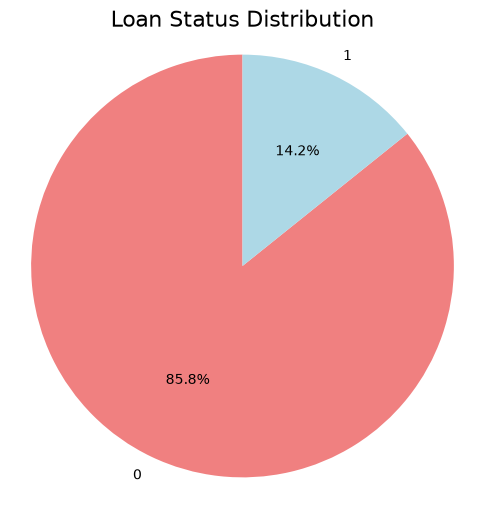

In [7]:
#Loan status distribution
loan_status_counts = df['loan_status'].value_counts()
labels = loan_status_counts.index
sizes = loan_status_counts.values


plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightcoral','lightblue']
)

plt.title('Loan Status Distribution', fontsize=16)
plt.axis('equal')
plt.show()

In [8]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
count,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


In [9]:
df_num = df.select_dtypes(include=['int64', 'float64']).drop(columns=['loan_status'])
df_num

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
0,37,35000,0.0,6000,11.49,0.17,14
1,22,56000,6.0,4000,13.35,0.07,2
2,29,28800,8.0,6000,8.90,0.21,10
3,30,70000,14.0,12000,11.11,0.17,5
4,22,60000,2.0,6000,6.92,0.10,3
...,...,...,...,...,...,...,...
58640,34,120000,5.0,25000,15.95,0.21,10
58641,28,28800,0.0,10000,12.73,0.35,8
58642,23,44000,7.0,6800,16.00,0.15,2
58643,22,30000,2.0,5000,8.90,0.17,3


array([[<Axes: title={'center': 'person_age'}>,
        <Axes: title={'center': 'person_income'}>,
        <Axes: title={'center': 'person_emp_length'}>],
       [<Axes: title={'center': 'loan_amnt'}>,
        <Axes: title={'center': 'loan_int_rate'}>,
        <Axes: title={'center': 'loan_percent_income'}>],
       [<Axes: title={'center': 'cb_person_cred_hist_length'}>, <Axes: >,
        <Axes: >]], dtype=object)

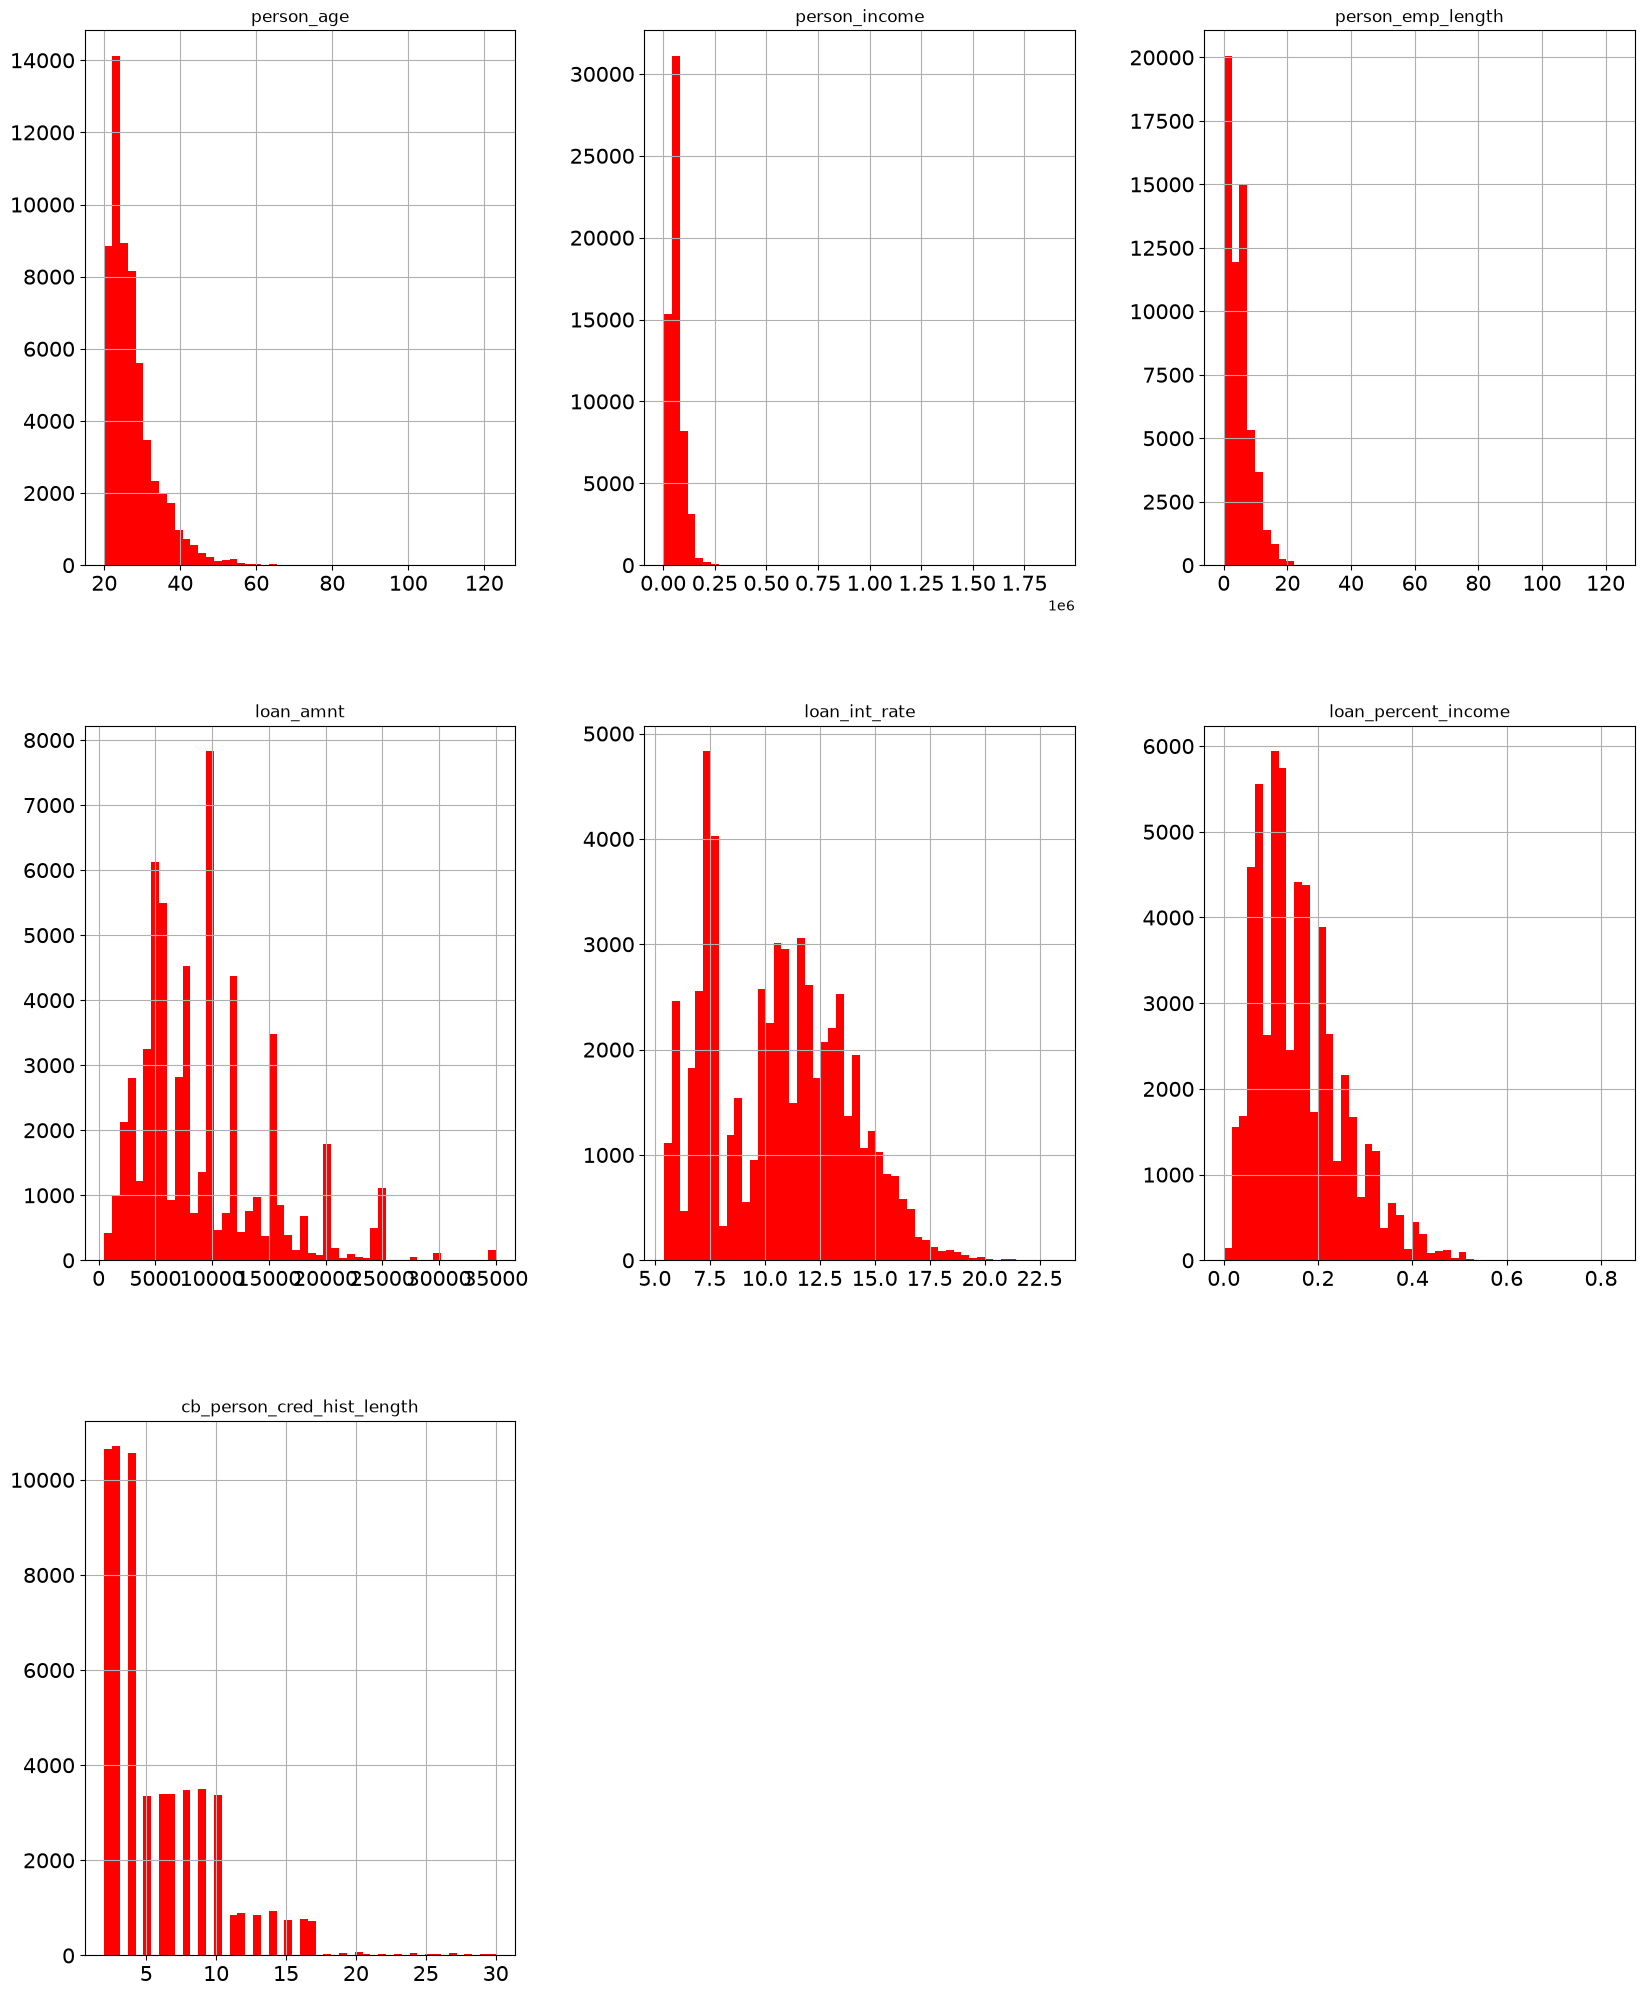

In [10]:
# Histogrames for numeerical features
df_num.hist(
    figsize=(20,25),
    bins=50,
    xlabelsize=15,
    ylabelsize=15,
    color='red'
)

In [11]:
df_obj = df.select_dtypes(include=['object'])
df_obj

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\1434897285.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_obj = df.select_dtypes(include=['object'])


,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file
0,RENT,EDUCATION,B,N
1,OWN,MEDICAL,C,N
2,OWN,PERSONAL,A,N
3,RENT,VENTURE,B,N
4,RENT,MEDICAL,A,N
...,...,...,...,...
58640,MORTGAGE,EDUCATION,D,Y
58641,RENT,MEDICAL,C,N
58642,RENT,EDUCATION,D,N
58643,RENT,EDUCATION,A,N


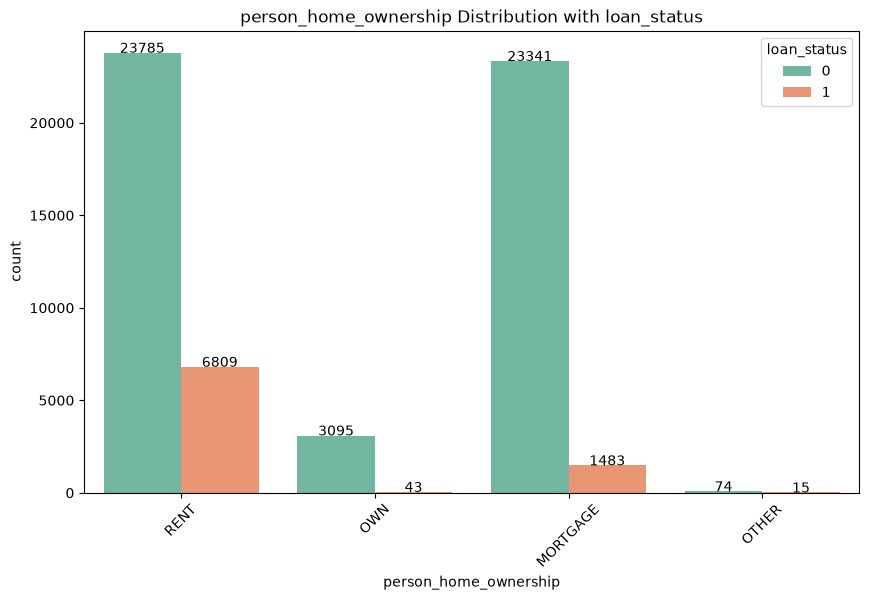

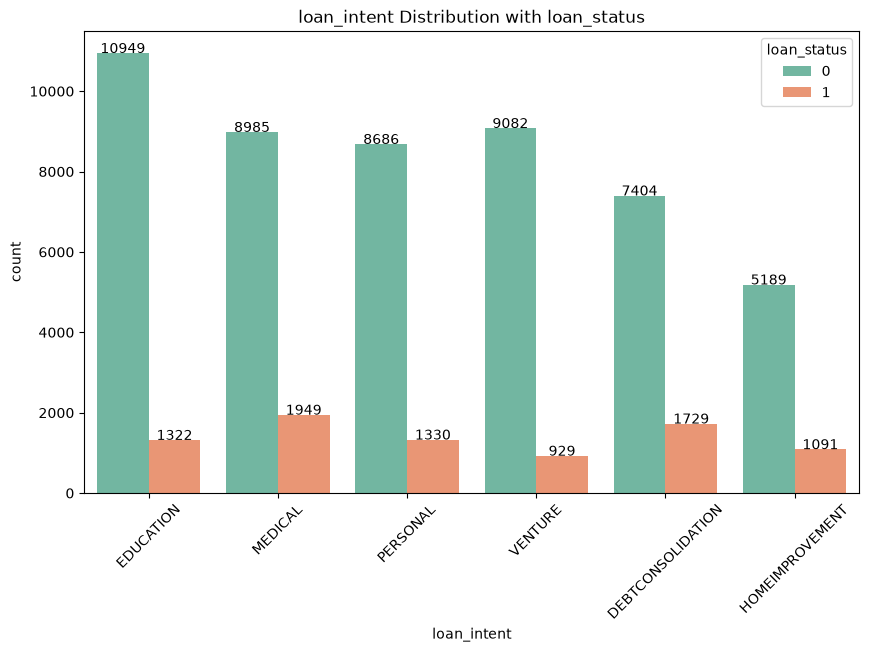

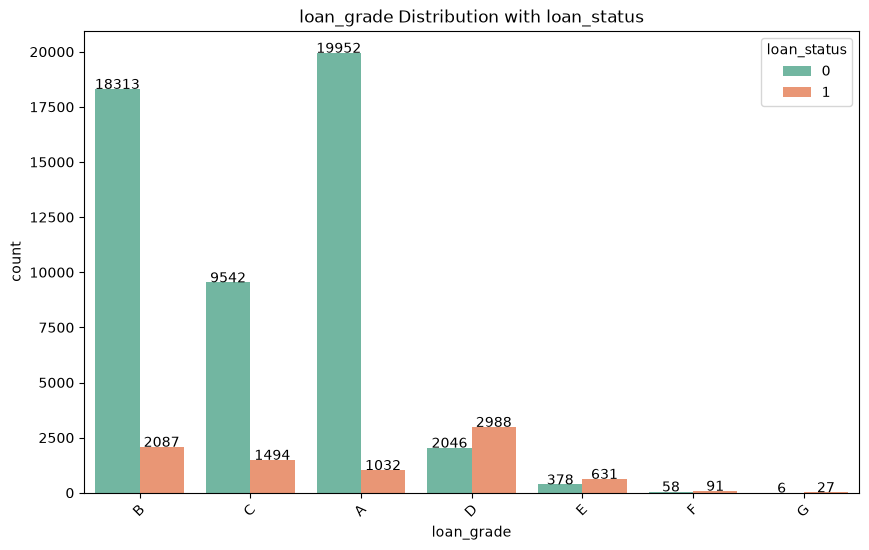

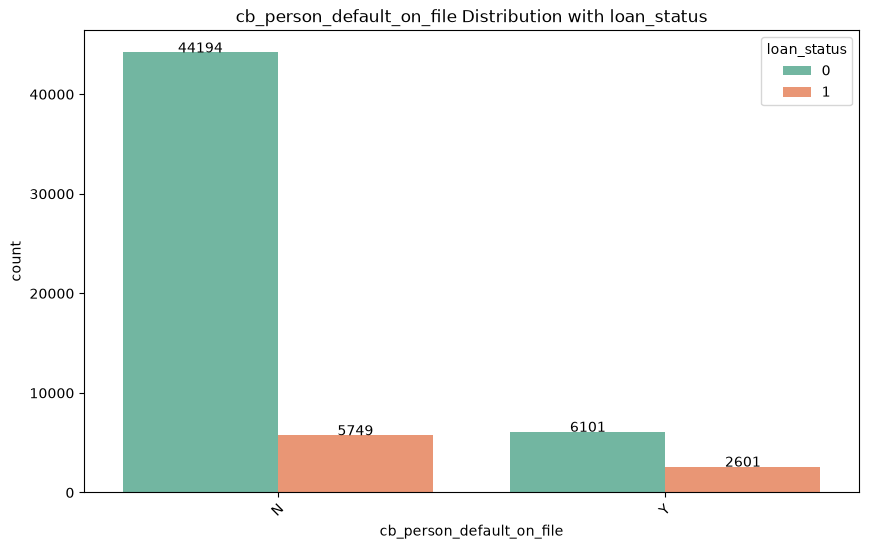

In [12]:
# Plotting every object feature
for col in df_obj:
    plt.figure(figsize=(10, 6))
    ax = sns.countplot(data=df, x=col, hue='loan_status', palette='Set2')
    plt.xticks(rotation=45)
    plt.title(f"{col} Distribution with loan_status")


    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.text(
                p.get_x() + p.get_width() / 2,
                height + 1,
                int(height),
                ha='center',
            )
    plt.show()

In [13]:
for col in df_obj.columns:
    print(pd.crosstab(df[col], df['loan_status'], normalize='index'))
    print("-"*50)

loan_status                   0         1
person_home_ownership                    
MORTGAGE               0.940259  0.059741
OTHER                  0.831461  0.168539
OWN                    0.986297  0.013703
RENT                   0.777440  0.222560
--------------------------------------------------
loan_status               0         1
loan_intent                          
DEBTCONSOLIDATION  0.810687  0.189313
EDUCATION          0.892266  0.107734
HOMEIMPROVEMENT    0.826274  0.173726
MEDICAL            0.821749  0.178251
PERSONAL           0.867212  0.132788
VENTURE            0.907202  0.092798
--------------------------------------------------
loan_status         0         1
loan_grade                     
A            0.950820  0.049180
B            0.897696  0.102304
C            0.864625  0.135375
D            0.406436  0.593564
E            0.374628  0.625372
F            0.389262  0.610738
G            0.181818  0.818182
--------------------------------------------------
loa

## Important notes:

#### The probability for getting the loan is you rent your house is almost 23%, for mortgage is 6% and for house owners is 2%. We assume that loan approval rate for renters is higher than for who own their houses as mortgage and for house owners, which is correct for mortgage case but it is not correct for own case.


#### The A loan grade for loans has the least loan approval rate which leaves us with a big question.

#### lastly, the person with default history has higher loan approval rate than those who does not, which is irrational.

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


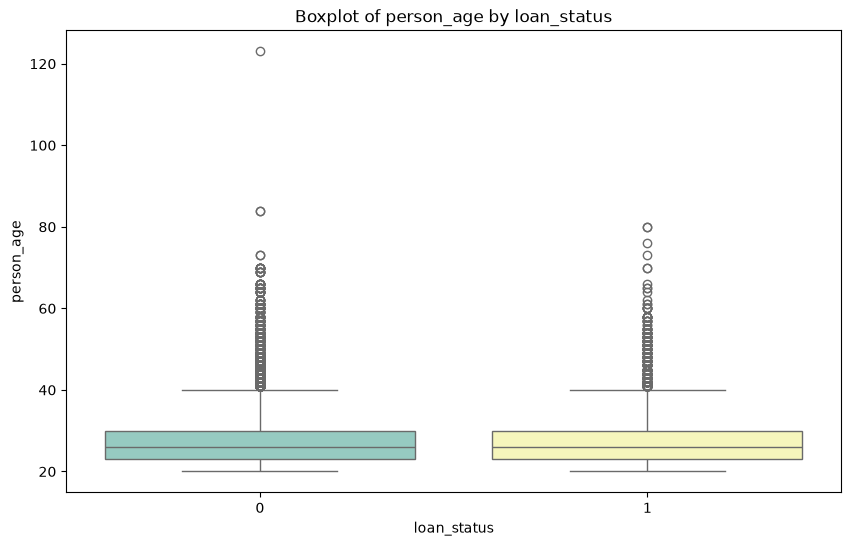

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


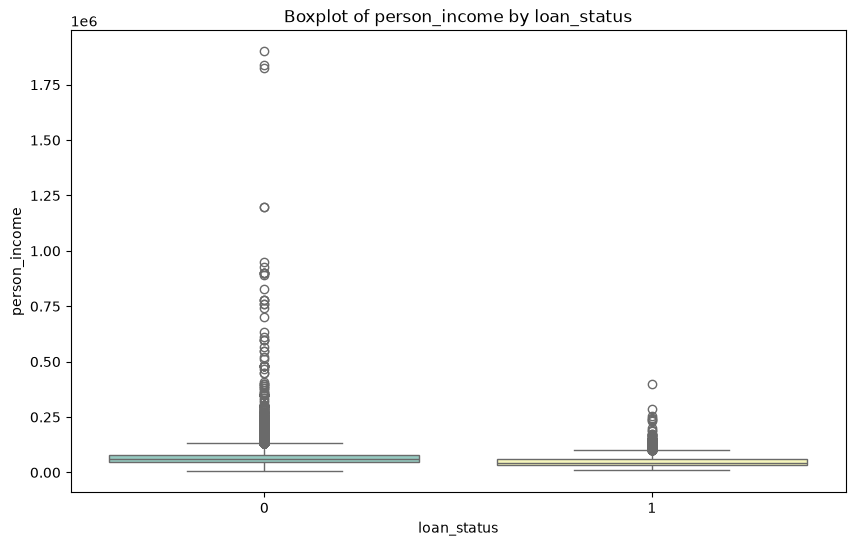

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


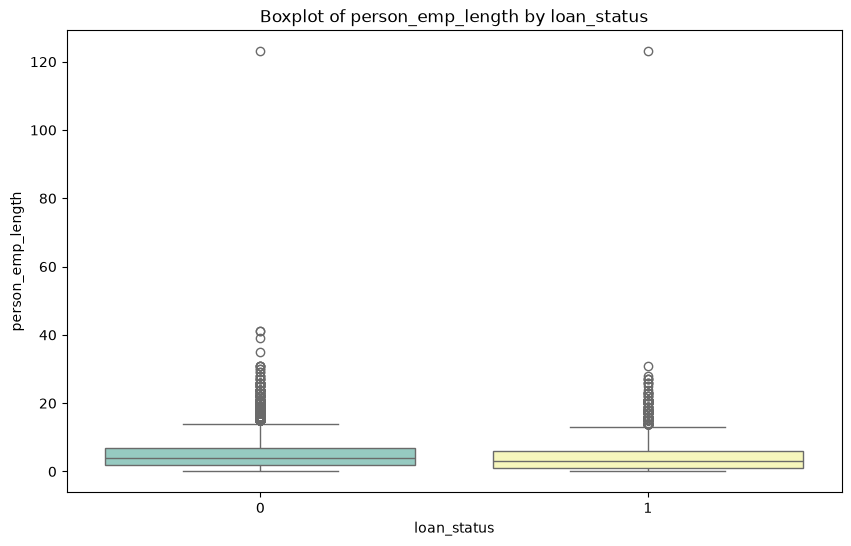

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


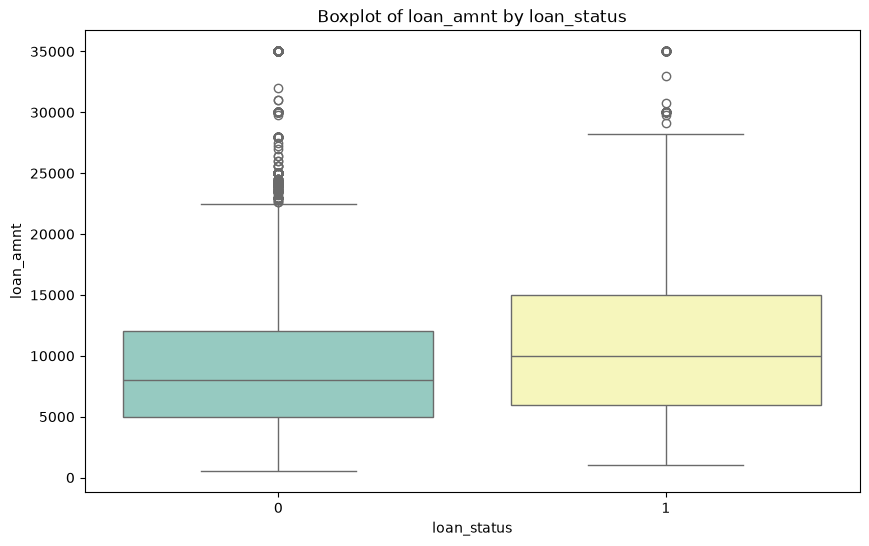

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


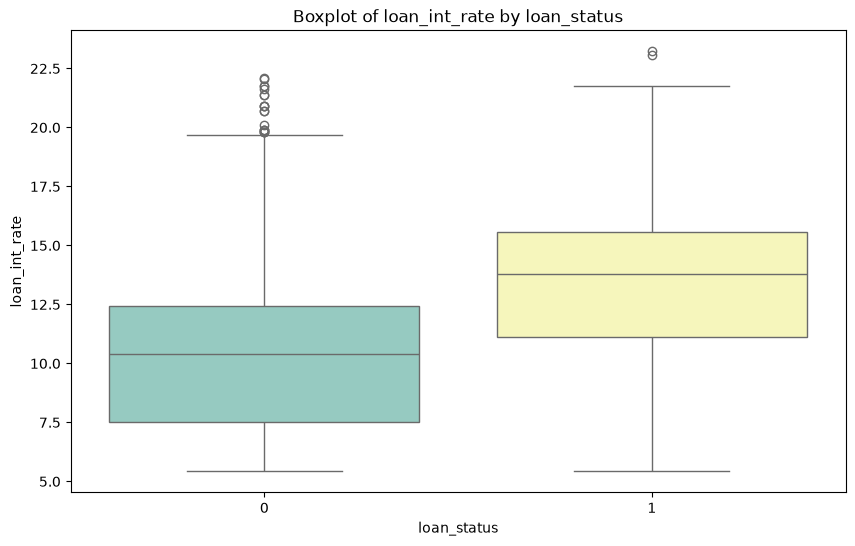

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


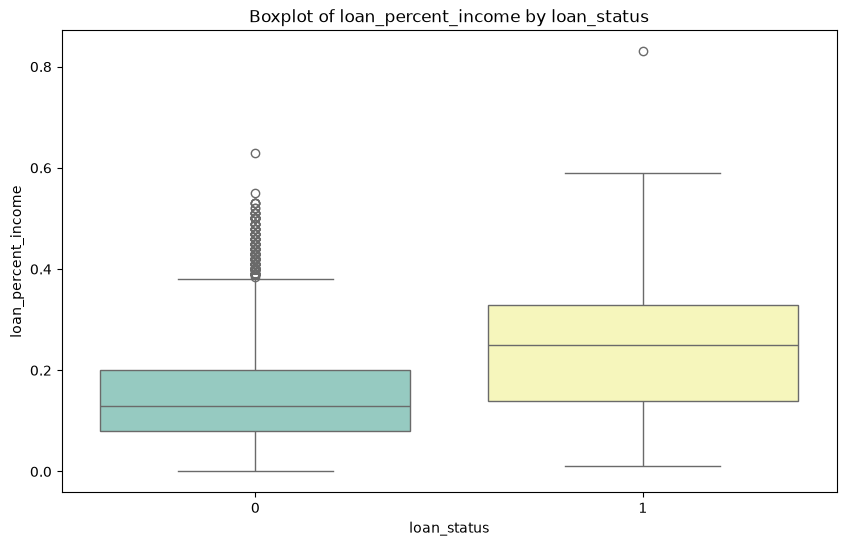

C:\Users\BETA\AppData\Local\Temp\ipykernel_10288\2459676345.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')


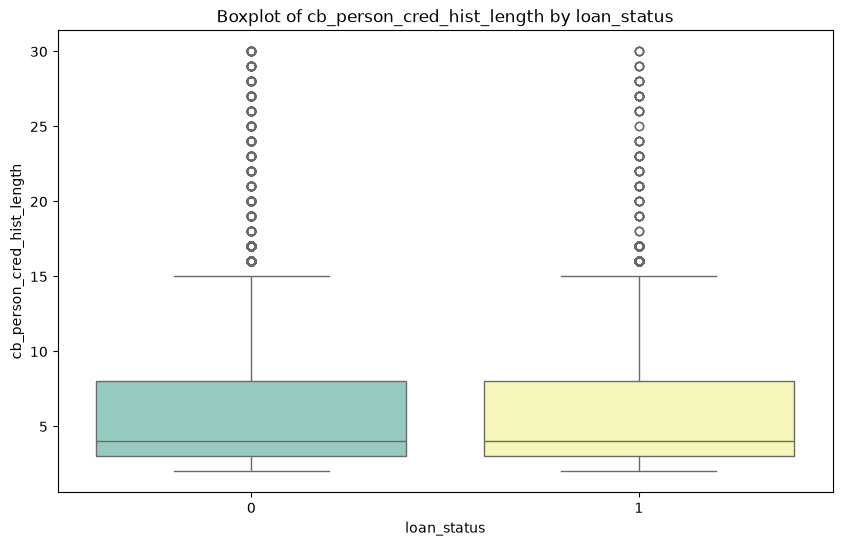

In [14]:
# Boxplots for numerical features
for col in df_num.columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x='loan_status', y=col, palette='Set3')
    plt.xlabel('loan_status')
    plt.ylabel(f"{col}")
    plt.title(f"Boxplot of {col} by loan_status")
    plt.show()

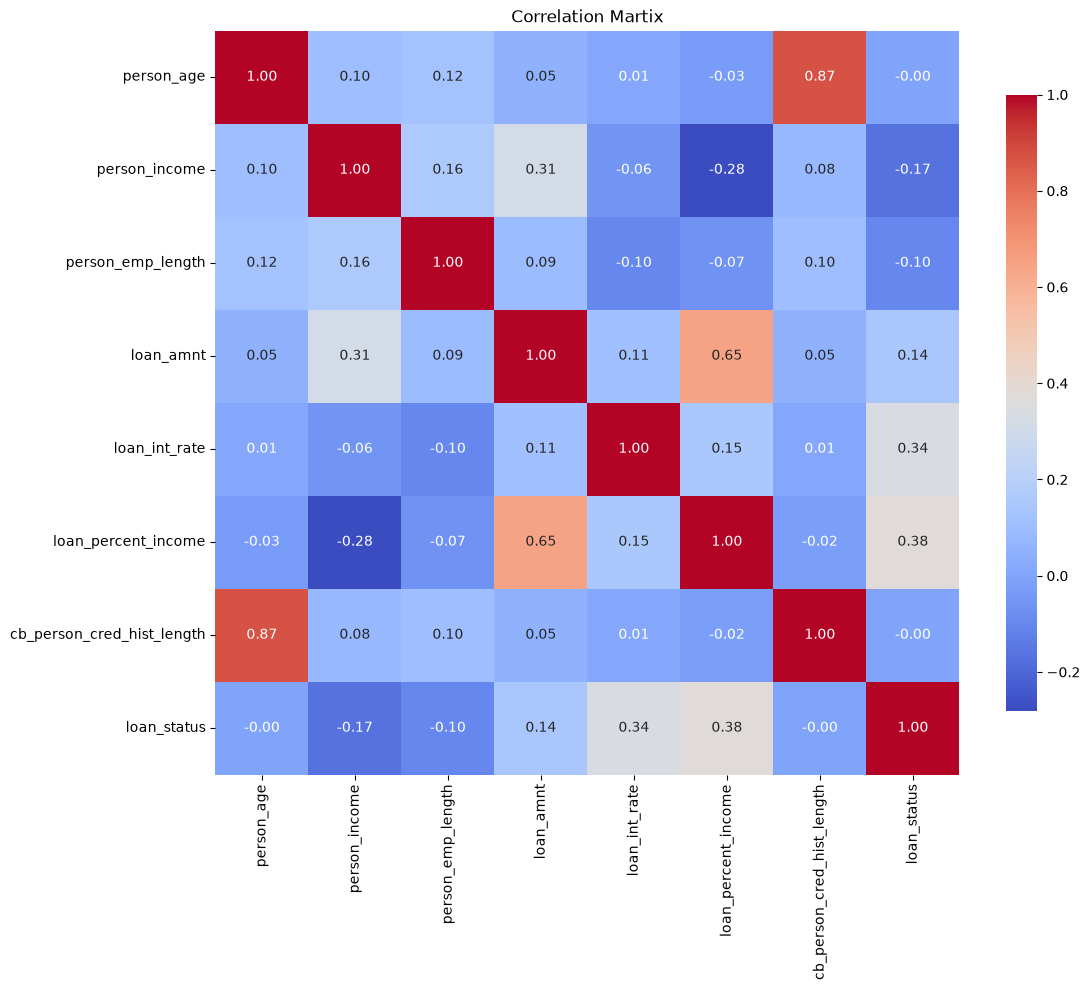

In [15]:
# Correlation matrix
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", square=True, cbar_kws={"shrink": .8})
plt.title('Correlation Martix')
plt.show()

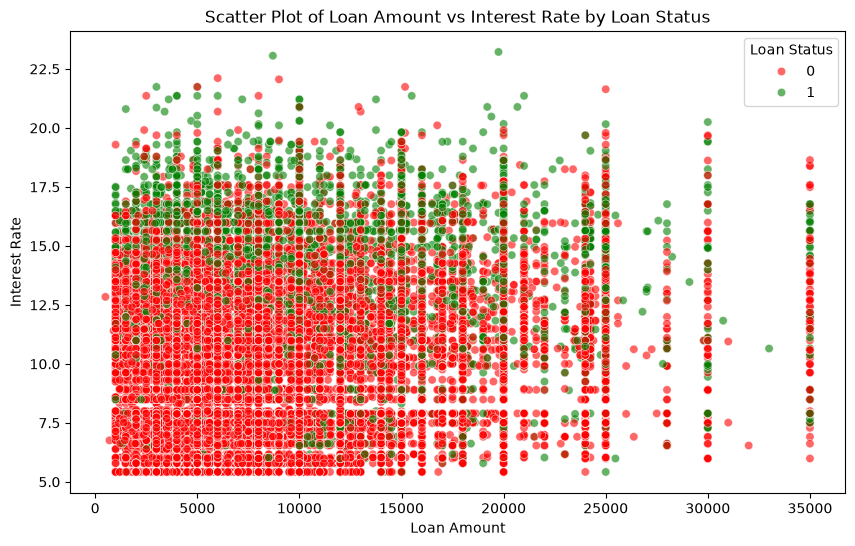

In [16]:
# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='loan_amnt', y='loan_int_rate', hue='loan_status', palette=['red', 'green'], alpha=0.6)
plt.title('Scatter Plot of Loan Amount vs Interest Rate by Loan Status')
plt.xlabel('Loan Amount')
plt.ylabel('Interest Rate')
plt.legend(title='Loan Status')
plt.show()

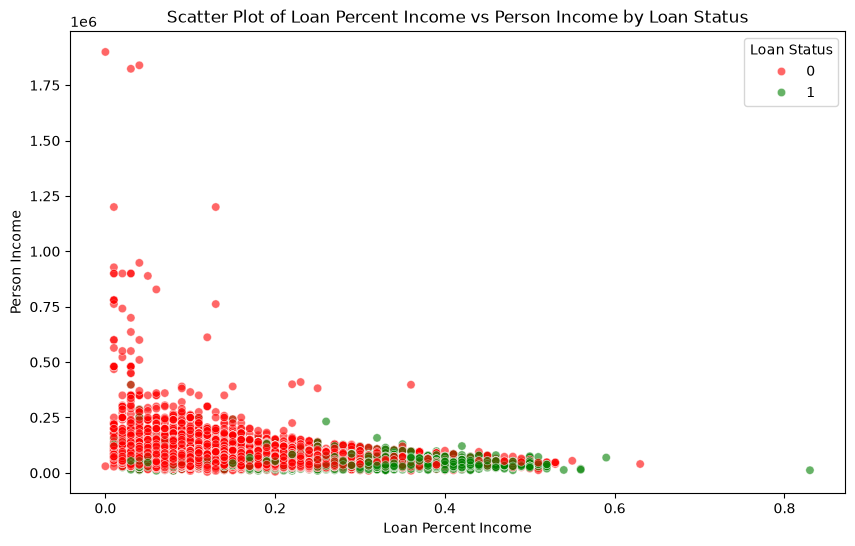

In [17]:
# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='loan_percent_income', y='person_income', hue='loan_status', palette=['red', 'green'], alpha=0.6)
plt.title('Scatter Plot of Loan Percent Income vs Person Income by Loan Status')
plt.xlabel('Loan Percent Income')
plt.ylabel('Person Income')
plt.legend(title='Loan Status')
plt.show()

In [18]:
# Handling missing values 
df.isnull().sum()

person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

In [19]:
# Handling outliers
for col in df_num.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Number of outliers in {col}: {len(outliers)}")
    print(f"Q1 = {Q1}")
    print(f"Q3 = {Q3}")
    print(f"IQR = {IQR}")
    print(f"Lower Bound = {lower_bound}")
    print(f"Upper Bound = {upper_bound}")
    print("-"*50)

Number of outliers in person_age: 2446
Q1 = 23.0
Q3 = 30.0
IQR = 7.0
Lower Bound = 12.5
Upper Bound = 40.5
--------------------------------------------------
Number of outliers in person_income: 2411
Q1 = 42000.0
Q3 = 75600.0
IQR = 33600.0
Lower Bound = -8400.0
Upper Bound = 126000.0
--------------------------------------------------
Number of outliers in person_emp_length: 1274
Q1 = 2.0
Q3 = 7.0
IQR = 5.0
Lower Bound = -5.5
Upper Bound = 14.5
--------------------------------------------------
Number of outliers in loan_amnt: 2045
Q1 = 5000.0
Q3 = 12000.0
IQR = 7000.0
Lower Bound = -5500.0
Upper Bound = 22500.0
--------------------------------------------------
Number of outliers in loan_int_rate: 34
Q1 = 7.88
Q3 = 12.99
IQR = 5.11
Lower Bound = 0.21499999999999897
Upper Bound = 20.655
--------------------------------------------------
Number of outliers in loan_percent_income: 1210
Q1 = 0.09
Q3 = 0.21
IQR = 0.12
Lower Bound = -0.09
Upper Bound = 0.39
----------------------------------

In [20]:
df_clean = df.copy()

In [21]:
# Handling outliers
for col in df_num.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]

print(f"Rows before: {df.shape[0]}")
print(f"Rows after: {df_clean.shape[0]}")
print(f"Rows removed: {df.shape[0] - df_clean.shape[0]} ({(1 - df_clean.shape[0]/df.shape[0])*100:.1f}%)")

df = df_clean.reset_index(drop=True)

Rows before: 58645
Rows after: 49882
Rows removed: 8763 (14.9%)


In [22]:
# Handling outliers
for col in df_num.columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    print(f"Number of outliers in {col}: {len(outliers)}")
    print(f"Q1 = {Q1}")
    print(f"Q3 = {Q3}")
    print(f"IQR = {IQR}")
    print(f"Lower Bound = {lower_bound}")
    print(f"Upper Bound = {upper_bound}")
    print("-"*50)

Number of outliers in person_age: 581
Q1 = 23.0
Q3 = 29.0
IQR = 6.0
Lower Bound = 14.0
Upper Bound = 38.0
--------------------------------------------------
Number of outliers in person_income: 1232
Q1 = 41000.0
Q3 = 72000.0
IQR = 31000.0
Lower Bound = -5500.0
Upper Bound = 118500.0
--------------------------------------------------
Number of outliers in person_emp_length: 0
Q1 = 2.0
Q3 = 7.0
IQR = 5.0
Lower Bound = -5.5
Upper Bound = 14.5
--------------------------------------------------
Number of outliers in loan_amnt: 238
Q1 = 5000.0
Q3 = 11000.0
IQR = 6000.0
Lower Bound = -4000.0
Upper Bound = 20000.0
--------------------------------------------------
Number of outliers in loan_int_rate: 0
Q1 = 7.88
Q3 = 12.98
IQR = 5.1000000000000005
Lower Bound = 0.22999999999999954
Upper Bound = 20.630000000000003
--------------------------------------------------
Number of outliers in loan_percent_income: 496
Q1 = 0.09
Q3 = 0.2
IQR = 0.11000000000000001
Lower Bound = -0.07500000000000004
Upper

In [23]:
#Encoding
df = pd.get_dummies(df, drop_first=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49882 entries, 0 to 49881
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   person_age                   49882 non-null  int64  
 1   person_income                49882 non-null  int64  
 2   person_emp_length            49882 non-null  float64
 3   loan_amnt                    49882 non-null  int64  
 4   loan_int_rate                49882 non-null  float64
 5   loan_percent_income          49882 non-null  float64
 6   cb_person_cred_hist_length   49882 non-null  int64  
 7   loan_status                  49882 non-null  int64  
 8   person_home_ownership_OTHER  49882 non-null  bool   
 9   person_home_ownership_OWN    49882 non-null  bool   
 10  person_home_ownership_RENT   49882 non-null  bool   
 11  loan_intent_EDUCATION        49882 non-null  bool   
 12  loan_intent_HOMEIMPROVEMENT  49882 non-null  bool   
 13  loan_intent_MEDICAL        

In [24]:
#Scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df[df_num.columns] = scaler.fit_transform(df[df_num.columns])
df.head()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status,person_home_ownership_OTHER,person_home_ownership_OWN,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
0,0.85,0.252874,0.000000,0.250000,0.399342,0.435897,0.923077,0,False,False,...,False,False,False,True,False,False,False,False,False,False
1,0.10,0.425287,0.428571,0.159091,0.521711,0.179487,0.000000,0,False,True,...,True,False,False,False,True,False,False,False,False,False
2,0.45,0.201970,0.571429,0.250000,0.228947,0.538462,0.615385,0,False,True,...,False,True,False,False,False,False,False,False,False,False
3,0.50,0.540230,1.000000,0.522727,0.374342,0.435897,0.230769,0,False,False,...,False,False,True,True,False,False,False,False,False,False
4,0.10,0.458128,0.142857,0.250000,0.098684,0.256410,0.076923,0,False,False,...,True,False,False,False,False,False,False,False,False,False


In [25]:
#Data Splitting
from sklearn.model_selection import train_test_split

x = df.drop(columns=['loan_status'])
y = df['loan_status']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_test: {y_test.shape}")

x_train: (39905, 22)
y_train: (39905,)
x_test: (9977, 22)
y_test: (9977,)


In [26]:
#Modeling
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

logistic_regression_model = LogisticRegression(max_iter=1000)
decision_tree_model = DecisionTreeClassifier()
random_forest_model = RandomForestClassifier()
gradient_boosting_model = GradientBoostingClassifier()
svm_model = SVC()
k_neighbors_model = KNeighborsClassifier()

models = {
    "Logistic Regression": logistic_regression_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "SVM": svm_model,
    "K-Nearest Neighbors": k_neighbors_model
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.4f}")

Logistic Regression Accuracy: 0.9093
Decision Tree Accuracy: 0.9121
Random Forest Accuracy: 0.9470
Gradient Boosting Accuracy: 0.9424
SVM Accuracy: 0.9357
K-Nearest Neighbors Accuracy: 0.9294


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(x_test)
    results.append({
        "Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

result_df = pd.DataFrame(results)
result_df

,Model Name,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.909291,0.754386,0.459191,0.570887
1,Decision Tree,0.912098,0.663404,0.672006,0.667677
2,Random Forest,0.946978,0.920430,0.652937,0.763945
3,Gradient Boosting,0.942367,0.897408,0.633867,0.742959
4,SVM,0.935652,0.889406,0.582761,0.704147
5,K-Nearest Neighbors,0.929438,0.845279,0.566743,0.678539
